In [68]:
# Downloading the Titanic dataset directly from a public URL to avoid FileNotFoundError
import pandas as pd

url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
print("Downloading and loading Titanic dataset...")
df = pd.read_csv(url)

# Standardize column names to lowercase to match the rest of the notebook
df.columns = df.columns.str.lower()

# Create a copy of the original dataset
orig_df = df.copy()
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [69]:
#Explore the Titanic dataset
#Print all samples and check how many samples and features the Titanic dataset has
print(orig_df)

     passengerid  survived  pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  name     sex   age  sibsp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                                 ...     ...   ... 

In [70]:
#Check the type of each variable (data type)
#int type is ok, float64 is ok as well but you may change it to int, object type need to be changed to int (object is a string in pandas and perform a string operation)
df.dtypes

,0
passengerid,int64
survived,int64
pclass,int64
name,object
sex,object
age,float64
sibsp,int64
parch,int64
ticket,object
fare,float64


In [71]:
#Use shape attribute to check the raws (samples) and columns (features)
df.shape

(891, 12)

In [72]:
#Use describe attribute to explore the data statistics
#Can you let me a little bit about the data, for example the age groups
df.describe()

,passengerid,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [73]:
#Use describe attribute at different location to explore the data statistics
#Use 3 or 4 instead of 2 to include more features (this is useful when you have lots of features)
df.describe().iloc[:,:2]

,passengerid,survived
count,891.000000,891.000000
mean,446.000000,0.383838
std,257.353842,0.486592
min,1.000000,0.000000
25%,223.500000,0.000000
50%,446.000000,0.000000
75%,668.500000,1.000000
max,891.000000,1.000000


In [74]:
#Use isnull() to find columns or rows with missing values and sum them up to get the total of missing values
#Which features are the leak features?
df.isnull().sum()

,0
passengerid,0
survived,0
pclass,0
name,0
sex,0
age,177
sibsp,0
parch,0
ticket,0
fare,0


In [75]:
#We can create a boolean array (a series with True or False to indicate if a row (a sample) has missing data)
#and use it to inspect rows that are missing data
mask = df.isnull()

In [76]:
mask.head()  # rows

,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,False,False,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,True,False


In [77]:
#Let's improve the process by using the function any that iterate through each row and return true for any x in the raw = true
mask = df.isnull().any(axis=1)

In [78]:
mask.head()

,0
0,True
1,False
2,True
3,False
4,True


In [79]:
df[mask].age.head() # check age column


,age
0,22.0
2,26.0
4,35.0
5,NaN
7,2.0


In [80]:
df[mask].embarked.head() # check embarked column

,embarked
0,S
2,S
4,S
5,Q
7,S


In [81]:
#Use the .value_counts method to examine the counts of the values:
df.sex.value_counts(dropna=False) # How many male and female
# Assign dropna to false if you don't want to delete the missing values

,count
sex,
male,577
female,314


In [82]:
#Use the .value_counts method to examine the counts of the values:
df.embarked.value_counts(dropna=False)

,count
embarked,
S,644
C,168
Q,77
NaN,2


In [83]:
#Use the .value_counts method to examine the counts of the values:
df.age.value_counts(dropna=False)

,count
age,
NaN,177
24.00,30
22.00,27
18.00,26
28.00,25
...,...
24.50,1
0.67,1
0.42,1


In [84]:
# Data preprocessing
import numpy as np
import pandas as pd

# Start fresh from orig_df to reconstruct with distinctive features
df = orig_df.copy()

# 1. Feature Engineering: Extract Title from the name
df['title'] = df['name'].str.extract(' ([A-Za-z]+)\.', expand=False)
# Group rare titles into broader categories
common_titles = ['Mr', 'Miss', 'Mrs', 'Master']
df['title'] = df['title'].replace(['Lady', 'Countess','Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
df['title'] = df['title'].replace('Mlle', 'Miss')
df['title'] = df['title'].replace('Ms', 'Miss')
df['title'] = df['title'].replace('Mme', 'Mrs')

# 2. Distinctive Imputation: Impute age based on Title group median
age_medians = df.groupby('title')['age'].median()
for title, median in age_medians.items():
    df.loc[(df['age'].isnull()) & (df['title'] == title), 'age'] = median
df['age'] = df['age'].fillna(df['age'].median())

# 3. Feature Engineering: Family size and Alone status
df['family_size'] = df['sibsp'] + df['parch'] + 1
df['is_alone'] = (df['family_size'] == 1).astype(int)

# 4. Fill missing Embarked values with the mode
df['embarked'] = df['embarked'].fillna('S')

# 5. Transform highly skewed numerical features (Fare)
df['fare_log'] = np.log1p(df['fare'])

# 6. Encode categorical values to numerical representations
df['sex'] = df['sex'].map({'male': 1, 'female': 0})
df['embarked'] = df['embarked'].map({'S': 2, 'C': 1, 'Q': 0})
df['title'] = df['title'].map({'Mr': 0, 'Miss': 1, 'Mrs': 2, 'Master': 3, 'Rare': 4})

# 7. Drop original non-numeric/redundant columns
columns_to_drop = ['name', 'ticket', 'cabin', 'fare']
df = df.drop(columns=columns_to_drop, errors='ignore')

print("Distinctive preprocessing completed. Features now available:")
print(df.columns.tolist())
print(df.head())

Distinctive preprocessing completed. Features now available:
['passengerid', 'survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'embarked', 'title', 'family_size', 'is_alone', 'fare_log']
   passengerid  survived  pclass  sex   age  sibsp  parch  embarked  title  \
0            1         0       3    1  22.0      1      0         2      0   
1            2         1       1    0  38.0      1      0         1      2   
2            3         1       3    0  26.0      0      0         2      1   
3            4         1       1    0  35.0      1      0         2      2   
4            5         0       3    1  35.0      0      0         2      0   

   family_size  is_alone  fare_log  
0            2         0  2.110213  
1            2         0  4.280593  
2            1         1  2.188856  
3            2         0  3.990834  
4            1         1  2.202765  


<>:9: SyntaxWarning: invalid escape sequence '\.'
<>:9: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_736/285173905.py:9: SyntaxWarning: invalid escape sequence '\.'
  df['title'] = df['name'].str.extract(' ([A-Za-z]+)\.', expand=False)


In [85]:
print(df)

     passengerid  survived  pclass  sex   age  sibsp  parch  embarked  title  \
0              1         0       3    1  22.0      1      0         2      0   
1              2         1       1    0  38.0      1      0         1      2   
2              3         1       3    0  26.0      0      0         2      1   
3              4         1       1    0  35.0      1      0         2      2   
4              5         0       3    1  35.0      0      0         2      0   
..           ...       ...     ...  ...   ...    ...    ...       ...    ...   
886          887         0       2    1  27.0      0      0         2      4   
887          888         1       1    0  19.0      0      0         2      1   
888          889         0       3    0  21.0      1      2         2      1   
889          890         1       1    1  26.0      0      0         1      0   
890          891         0       3    1  32.0      0      0         0      0   

     family_size  is_alone  fare_log  


In [86]:
#Splitting data into training and testing datasets
from sklearn.model_selection import train_test_split
#Assign survived column (targets) to y
y = df.survived
#Delete survived column from X (samples)
X = df.drop(columns="survived")
#Now split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=11)

In [87]:
#check the y_train (target)
print(y_train)

503    0
74     1
300    1
658    0
461    0
      ..
269    1
337    1
91     0
80     0
703    0
Name: survived, Length: 623, dtype: int64


In [88]:
#check the X_train (samples)
print(X_train)

     passengerid  pclass  sex   age  sibsp  parch  embarked  title  \
503          504       3    0  37.0      0      0         2      1   
74            75       3    1  32.0      0      0         2      0   
300          301       3    0  21.0      0      0         0      1   
658          659       2    1  23.0      0      0         2      0   
461          462       3    1  34.0      0      0         2      0   
..           ...     ...  ...   ...    ...    ...       ...    ...   
269          270       1    0  35.0      0      0         2      1   
337          338       1    0  41.0      0      0         1      1   
91            92       3    1  20.0      0      0         2      0   
80            81       3    1  22.0      0      0         2      0   
703          704       3    1  25.0      0      0         0      0   

     family_size  is_alone  fare_log  
503            1         1  2.359674  
74             1         1  4.051712  
300            1         1  2.169054  
658

In [89]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Split features and labels using the newly engineered dataset
y = df['survived']
# Drop target column and unique identifiers that won't generalize
X = df.drop(columns=['survived', 'passengerid'])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=11)

# Fit Logistic Regression model
clf = LogisticRegression(solver='liblinear')
clf.fit(X_train, y_train)

# Make predictions
predicted = clf.predict(X_test)
expected = y_test

print("Upgraded Logistic Regression Model trained successfully on engineered features!")
print(f"New Logistic Regression Accuracy: {clf.score(X_test, y_test):.2%}")

Upgraded Logistic Regression Model trained successfully on engineered features!
New Logistic Regression Accuracy: 85.82%


In [96]:
# Compare a few predictions directly to actual outcomes
pd.DataFrame({'Actual': y_test, 'Predicted': predicted}).head(10)

,Actual,Predicted
431,1,1
821,1,0
629,0,0
626,0,0
665,0,0
582,0,0
250,0,0
780,1,1
728,0,0
259,1,1


In [91]:
#Save and test the model
import pickle

# Save the trained model as a pickle string.
saved_model = pickle.dumps(clf)

# Load the pickled model
clf_from_pickle = pickle.loads(saved_model)

# Use the loaded pickled model to make predictions
clf_from_pickle.predict(X_test)

array([1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 1, 1, 0])

In [92]:
# To save a machine learning model produced by scikit-learn (sklearn), you can use Python's joblib library,
# which is often preferred for saving scikit-learn models due to its efficiency.

#First, ensure you have the joblib library installed. If you don't have it, you can install it using pip:

# pip install joblib

# Once you have your scikit-learn model trained and ready to save, import joblib:
import joblib


# Save the model as a pickle in a file
# You can use the joblib.dump() function. Provide the model and the file path where you want to save it:
joblib.dump(clf, 'filename.pkl')

# Load the model from the file
# Your scikit-learn model is now saved to the specified file with the ".pkl" extension.
# To load the model at a later time for use, you can use joblib.load():
clf_from_joblib = joblib.load('filename.pkl')

# Use the loaded model to make predictions
clf_from_joblib.predict(X_test)

# This process allows you to save and load scikit-learn models efficiently, preserving their state for future use without the need to retrain them.

array([1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 1, 1, 0])

### Challenge 1: Comprehensive Model Evaluation

While raw accuracy is helpful, we often need a deeper understanding of our model's performance on a dataset like Titanic where survival is class-imbalanced.

Use the `classification_report` and `confusion_matrix` from `sklearn.metrics` to evaluate the predictions on your test dataset.

Confusion Matrix:
[[158  18]
 [ 20  72]]

Classification Report:
                 precision    recall  f1-score   support

Did Not Survive       0.89      0.90      0.89       176
       Survived       0.80      0.78      0.79        92

       accuracy                           0.86       268
      macro avg       0.84      0.84      0.84       268
   weighted avg       0.86      0.86      0.86       268



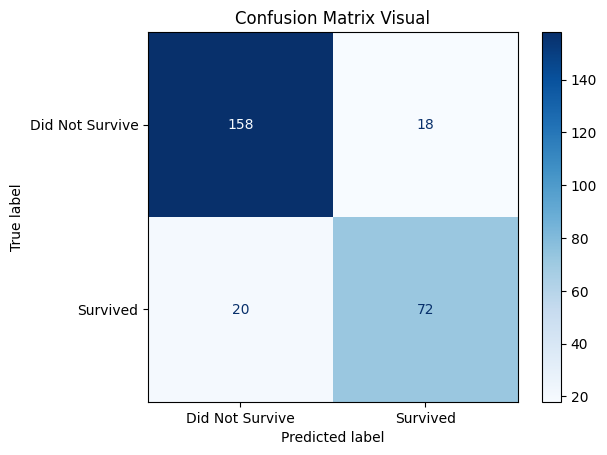

In [93]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Generate and print the confusion matrix
cm = confusion_matrix(expected, predicted)
print("Confusion Matrix:")
print(cm)

# 2. Print the classification report
print("\nClassification Report:")
print(classification_report(expected, predicted, target_names=['Did Not Survive', 'Survived']))

# 3. Plot the confusion matrix for better visualization
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Did Not Survive', 'Survived'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix Visual")
plt.show()

### Challenge 2: K-Fold Cross-Validation

To ensure your model generalizes well and doesn't depend heavily on a specific random split, evaluate your Logistic Regression classifier using **K-Fold Cross-Validation**.

In [94]:
from sklearn.model_selection import cross_val_score

# Perform 5-fold cross-validation
scores = cross_val_score(clf, X, y, cv=5)

print("Cross-validation scores:", scores)
print(f"Mean CV Accuracy: {scores.mean():.2%}")
print(f"Standard Deviation of CV Accuracy: {scores.std():.2%}")

Cross-validation scores: [0.79888268 0.80898876 0.78089888 0.82022472 0.83146067]
Mean CV Accuracy: 80.81%
Standard Deviation of CV Accuracy: 1.74%


### Challenge 3: Try a Different Classifier (Random Forest)

Logistic Regression is a linear model. Let's see if a non-linear ensemble model like a **Random Forest Classifier** can capture more complex interactions between features and achieve higher performance.